# Task 2 — Real Estate Housing Price Prediction (OLS vs Ridge vs Lasso)

**Goal:** Predict median house value on the California Housing dataset with continuous regression, feature engineering and residual error analysis.

**Pipeline:**
1. Load data and explore it (nulls, distributions, correlation heatmap)
2. Impute missing values
3. Engineer interaction / ratio features
4. Detect multicollinearity using VIF
5. Standardize numeric features and one-hot encode the categorical feature
6. Compare **OLS**, **Ridge (L2)** and **Lasso (L1)** using RMSE, MAE and R² (alpha tuned with `GridSearchCV`)
7. Residual analysis of the best model

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Load the dataset

In [2]:
# housing.csv = California Housing (1990 census) with the `ocean_proximity` column and some missing values
LOCAL = "housing.csv"
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Exploratory Data Analysis

In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values per column:
total_bedrooms    207
dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


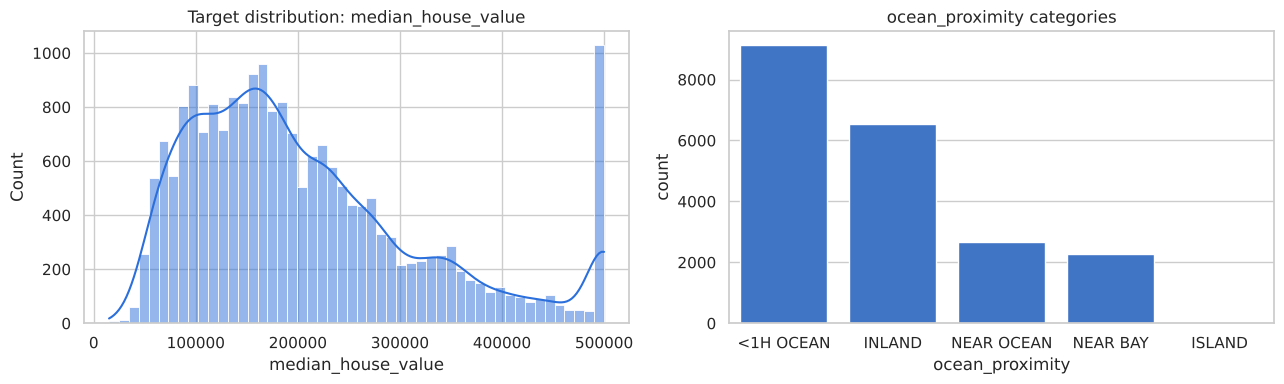

Houses capped at the max value 500001: 965


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=50, kde=True, ax=axes[0], color="#2a6fdb")
axes[0].set_title("Target distribution: median_house_value")
sns.countplot(data=df, x="ocean_proximity", order=df["ocean_proximity"].value_counts().index, ax=axes[1], color="#2a6fdb")
axes[1].set_title("ocean_proximity categories")
plt.tight_layout(); plt.show()
print("Houses capped at the max value 500001:", (df['median_house_value'] >= 500001).sum())

### Correlation heatmap (raw numeric features)

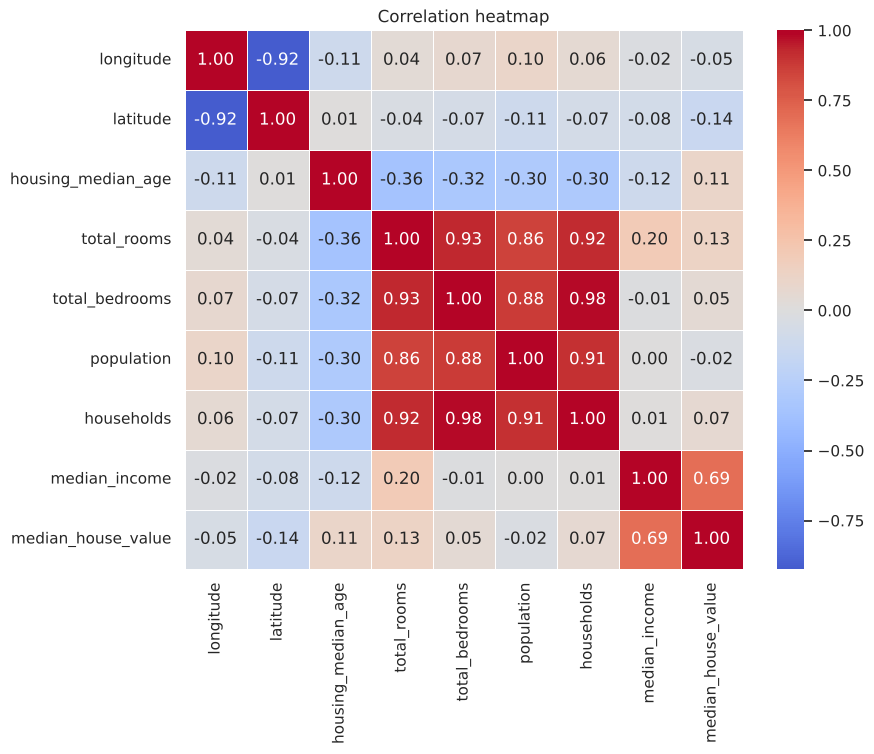

In [5]:
num_cols_raw = df.select_dtypes(include=np.number).columns.tolist()
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols_raw].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation heatmap")
plt.show()

**Observations:** `median_income` has the strongest correlation with the target. `total_rooms`, `total_bedrooms`, `population` and `households` are highly correlated with each other, which is a clear sign of **multicollinearity**. This is exactly the situation where Ridge/Lasso should help.

## 3. Feature engineering

In [6]:
def add_features(d):
    d = d.copy()
    d["rooms_per_household"]      = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"]        = d["total_bedrooms"] / d["total_rooms"]
    d["population_per_household"] = d["population"] / d["households"]
    # interaction features
    d["income_x_rooms_per_hh"]    = d["median_income"] * d["rooms_per_household"]
    d["income_x_house_age"]       = d["median_income"] * d["housing_median_age"]
    return d

df_fe = add_features(df)
df_fe[["rooms_per_household", "bedrooms_per_room", "population_per_household",
       "income_x_rooms_per_hh", "income_x_house_age"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
income_x_rooms_per_hh,20640.0,22.550365,17.923133,0.856971,11.686844,18.021764,27.864426,612.966667
income_x_house_age,20640.0,108.008027,74.386418,1.625000,57.997425,92.502950,140.104900,780.005200


## 4. Train / test split (80/20)
Split **before** imputing and scaling, so test data never leaks into the preprocessing.

In [7]:
TARGET = "median_house_value"
X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

cat_cols = ["ocean_proximity"]
num_cols = [c for c in X.columns if c not in cat_cols]
print("Numeric features:", len(num_cols), "| Categorical:", cat_cols)

Train: (16512, 14) | Test: (4128, 14)
Numeric features: 13 | Categorical: ['ocean_proximity']


## 5. Handle missing values and check multicollinearity (VIF)

In [8]:
imputer = SimpleImputer(strategy="median").fit(X_train[num_cols])
X_train_imp = pd.DataFrame(imputer.transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
print("Nulls left after imputation:", int(X_train_imp.isna().sum().sum()))

def vif_table(frame):
    # VIF_i = 1 / (1 - R²_i), where R²_i comes from regressing feature i on all the other features
    Z = StandardScaler().fit_transform(frame)
    out = []
    for i, col in enumerate(frame.columns):
        others = np.delete(Z, i, axis=1)
        r2 = LinearRegression().fit(others, Z[:, i]).score(others, Z[:, i])
        out.append((col, 1 / (1 - r2) if r2 < 1 else np.inf))
    return pd.DataFrame(out, columns=["feature", "VIF"]).sort_values("VIF", ascending=False).reset_index(drop=True)

vif = vif_table(X_train_imp)
vif

Nulls left after imputation: 0


,feature,VIF
0,total_bedrooms,50.989078
1,households,47.067224
2,median_income,21.053293
3,total_rooms,19.610286
4,income_x_rooms_per_hh,18.001943
5,latitude,9.605782
6,longitude,9.242275
7,income_x_house_age,9.191142
8,population,6.871230
9,housing_median_age,5.503685


A VIF above ~10 indicates serious multicollinearity. `latitude` and `longitude` (strongly tied to each other geographically), plus `total_bedrooms`, `households`, `total_rooms` and `median_income` (with its interaction term) exceed this threshold, so OLS coefficients can be unstable. Ridge (shrinks) and Lasso (shrinks and selects) are the standard remedies.

*Note: I tried a `latitude × longitude` interaction first, but it had a VIF above 10,000, so I dropped it as a useless feature.*

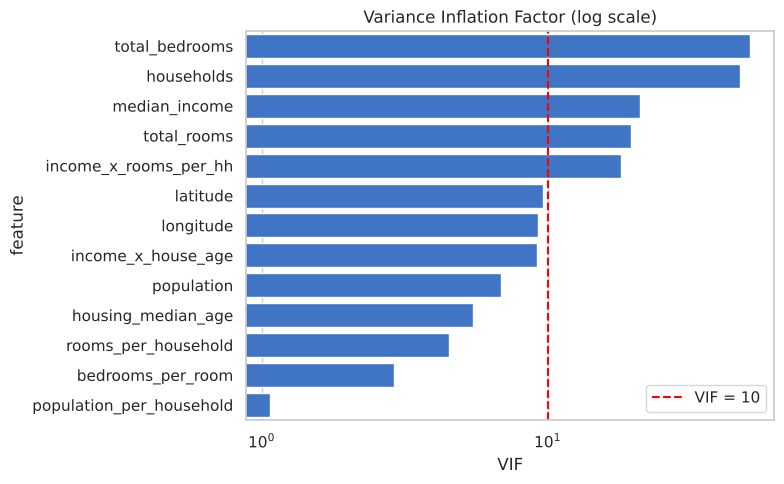

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(data=vif, y="feature", x="VIF", color="#2a6fdb")
plt.axvline(10, color="red", ls="--", label="VIF = 10")
plt.xscale("log"); plt.legend(); plt.title("Variance Inflation Factor (log scale)")
plt.tight_layout(); plt.show()

## 6. Preprocessing pipeline: impute → standardize → one-hot encode

In [10]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

## 7. Models: OLS vs Ridge (L2) vs Lasso (L1) with GridSearchCV

In [11]:
def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

# OLS has no hyperparameters, so it is fitted directly
ols = make_pipe(LinearRegression()).fit(X_train, y_train)

# Ridge: tune alpha with 5-fold CV
ridge_gs = GridSearchCV(
    make_pipe(Ridge(random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-4, 3, 15)},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)

# Lasso: tune alpha with 5-fold CV
lasso_gs = GridSearchCV(
    make_pipe(Lasso(max_iter=20000, random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-4, 2, 13)},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)

print("Best Ridge alpha:", ridge_gs.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_gs.best_params_["model__alpha"])

models = {"OLS": ols, "Ridge (L2)": ridge_gs.best_estimator_, "Lasso (L1)": lasso_gs.best_estimator_}

Best Ridge alpha: 1.0
Best Lasso alpha: 3.1622776601683795


## 8. Model comparison — RMSE, MAE, R²

In [12]:
rows = []
for name, m in models.items():
    for split, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        p = m.predict(Xs)
        rows.append({"model": name, "split": split,
                     "RMSE": np.sqrt(mean_squared_error(ys, p)),
                     "MAE": mean_absolute_error(ys, p),
                     "R2": r2_score(ys, p)})
results = pd.DataFrame(rows)
test_res = results[results.split == "test"].set_index("model")[["RMSE", "MAE", "R2"]].round(4)
print("=== Test-set performance ===")
display(test_res)
print("=== Train vs test (overfitting check) ===")
display(results.pivot(index="model", columns="split", values="R2").round(4))

=== Test-set performance ===


,RMSE,MAE,R2
model,,,
OLS,68845.0016,49458.6655,0.6383
Ridge (L2),68855.2291,49465.3454,0.6382
Lasso (L1),68849.6785,49460.4619,0.6383


=== Train vs test (overfitting check) ===


split,test,train
model,,
Lasso (L1),0.6383,0.6605
OLS,0.6383,0.6605
Ridge (L2),0.6382,0.6605


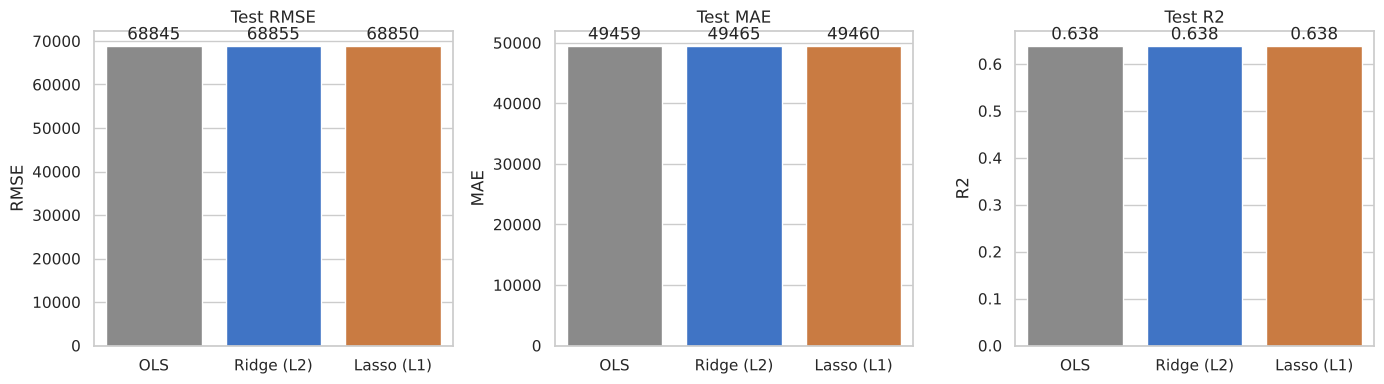

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    sns.barplot(x=test_res.index, y=test_res[metric], ax=ax, palette=["#8a8a8a", "#2a6fdb", "#e0782b"])
    ax.set_title(f"Test {metric}"); ax.set_xlabel("")
    for c in ax.containers: ax.bar_label(c, fmt="%.3f" if metric == "R2" else "%.0f", padding=2)
plt.tight_layout(); plt.show()

### Coefficient comparison: how regularisation changes the weights

Features zeroed out by Lasso: none


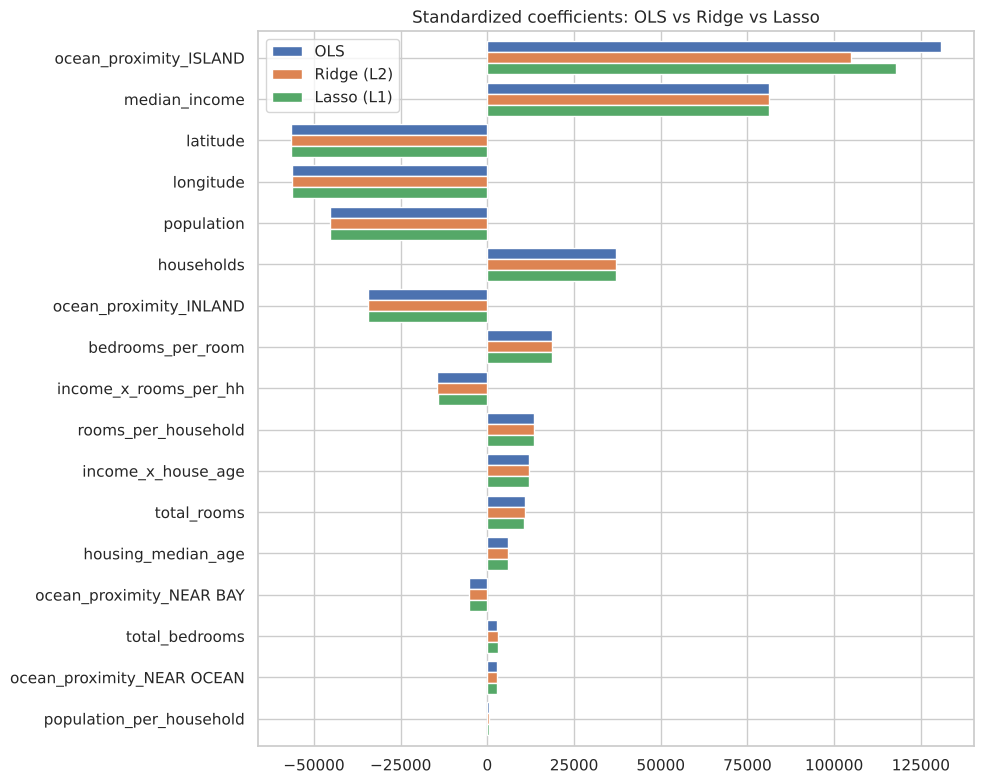

In [14]:
feat_names = models["OLS"].named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({name: m.named_steps["model"].coef_ for name, m in models.items()}, index=feat_names)
coefs.index = [i.split("__")[1] for i in coefs.index]
print("Features zeroed out by Lasso:", list(coefs.index[coefs["Lasso (L1)"] == 0]) or "none")

coefs.sort_values("OLS", key=abs, ascending=False).plot.barh(figsize=(10, 8), width=.8)
plt.gca().invert_yaxis(); plt.title("Standardized coefficients: OLS vs Ridge vs Lasso"); plt.tight_layout(); plt.show()

## 9. Residual error analysis (best model)

Best model by test RMSE: OLS
Mean residual: 798.4 | Std: 68848.7


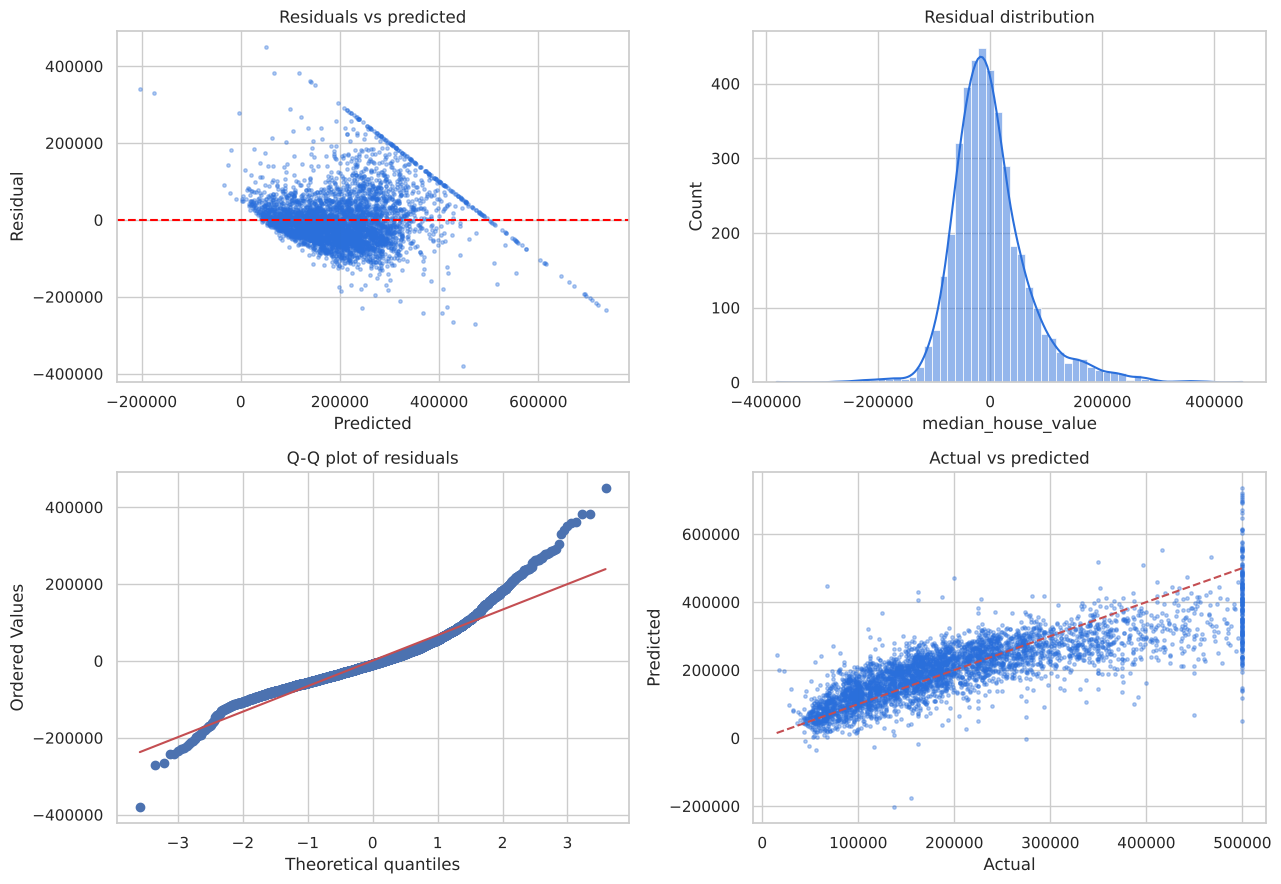

In [15]:
best_name = test_res["RMSE"].idxmin()
best = models[best_name]
pred = best.predict(X_test)
resid = y_test - pred
print(f"Best model by test RMSE: {best_name}")
print(f"Mean residual: {resid.mean():.1f} | Std: {resid.std():.1f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].scatter(pred, resid, s=6, alpha=.35, color="#2a6fdb")
axes[0,0].axhline(0, color="red", ls="--"); axes[0,0].set(title="Residuals vs predicted", xlabel="Predicted", ylabel="Residual")
sns.histplot(resid, bins=60, kde=True, ax=axes[0,1], color="#2a6fdb"); axes[0,1].set(title="Residual distribution")
stats.probplot(resid, dist="norm", plot=axes[1,0]); axes[1,0].set_title("Q-Q plot of residuals")
axes[1,1].scatter(y_test, pred, s=6, alpha=.35, color="#2a6fdb")
lims = [y_test.min(), y_test.max()]; axes[1,1].plot(lims, lims, "r--")
axes[1,1].set(title="Actual vs predicted", xlabel="Actual", ylabel="Predicted")
plt.tight_layout(); plt.show()

**Residual findings:**
- Residuals are centred near 0 (no systematic bias overall), but the spread increases for higher predicted prices (**heteroscedasticity**).
- The Q-Q plot shows heavy tails, so residuals are not perfectly normal.
- A horizontal band at the top of the actual-vs-predicted plot comes from the dataset **capping** prices at 500,001. Linear models cannot capture this ceiling.

In [16]:
# Where does the model make its biggest mistakes? Error by ocean_proximity
err = pd.DataFrame({"ocean_proximity": X_test["ocean_proximity"], "abs_error": resid.abs()})
err.groupby("ocean_proximity")["abs_error"].agg(["mean", "median", "count"]).round(0).sort_values("mean", ascending=False)

,mean,median,count
ocean_proximity,,,
ISLAND,81046.0,81046.0,1
NEAR BAY,65837.0,56088.0,436
NEAR OCEAN,59450.0,47992.0,572
<1H OCEAN,51367.0,39611.0,1795
INLAND,37138.0,26858.0,1324


## 10. Conclusion

| Aspect | Result |
|---|---|
| Multicollinearity | VIF analysis showed severe collinearity (rooms, bedrooms, households, population and the engineered/interaction features) |
| OLS vs Ridge vs Lasso | Test RMSE / MAE / R² are almost identical for all three (R² ≈ 0.64). With ~16k training rows and only ~14 features, overfitting is minimal (train R² ≈ test R²), so regularisation has little to fix |
| Regularisation effect | `GridSearchCV` picked modest alphas (Ridge ≈ 1, Lasso ≈ 3), and all three models score within ~0.01 R² of each other, so shrinkage mainly changes coefficient stability, not accuracy. Lasso did not need to zero out any feature |
| Residuals | Roughly unbiased, but heteroscedastic with heavy tails and a price-cap artefact |

**Next steps to improve accuracy:** log-transform the target, add `PolynomialFeatures`, or try non-linear models (Random Forest / Gradient Boosting) since the relationship with location is non-linear.